Laboratorul 3 – Partea 2: K-Means Clustering

Antrenarea K-Means pe datele reduse cu PCA (98%, 95%, 90%, 80%), alegerea numărului de clustere
(metoda cotului și silhouette), vizualizări și comparația metodelor de scalare.

In [1]:
import sys
from pathlib import Path

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists()), None)
assert ROOT is not None, "Ruleaza notebook-ul din interiorul folderului proiectului (ames-housing-ML)."
DATA_PROCESSED = ROOT / "data" / "processed"
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

from lab3_common import preprocess, cluster_profile

RANDOM_STATE = 42
THRESHOLDS = [0.98, 0.95, 0.90, 0.80]

df = pd.read_csv( ROOT/ "df.csv")
X_scaled, y, pipeline = preprocess(df, scaling="minmax", log=False)

pcas, X_pca = {}, {}
for t in THRESHOLDS:
    pcas[t] = PCA(n_components=t, svd_solver="full").fit(X_scaled)
    X_pca[t] = pcas[t].transform(X_scaled)
    print(f"{t:.0%}: {X_pca[t].shape[1]} componente")

98%: 142 componente
95%: 106 componente
90%: 79 componente
80%: 50 componente


Date și PCA:
Datele sunt preprocesate cu `preprocess()` din Partea 1 (295 de features, fără `SalePrice`) și reduse cu PCA:
98% → 142, 95% → 106, 90% → 79, 80% → 50 de componente.


Alegerea lui k:
Antrenăm K-Means pentru k = 2…10 pe fiecare prag. Alegem k după „cotul” curbei inertiei
și după valoarea maximă a silhouette score-ului.

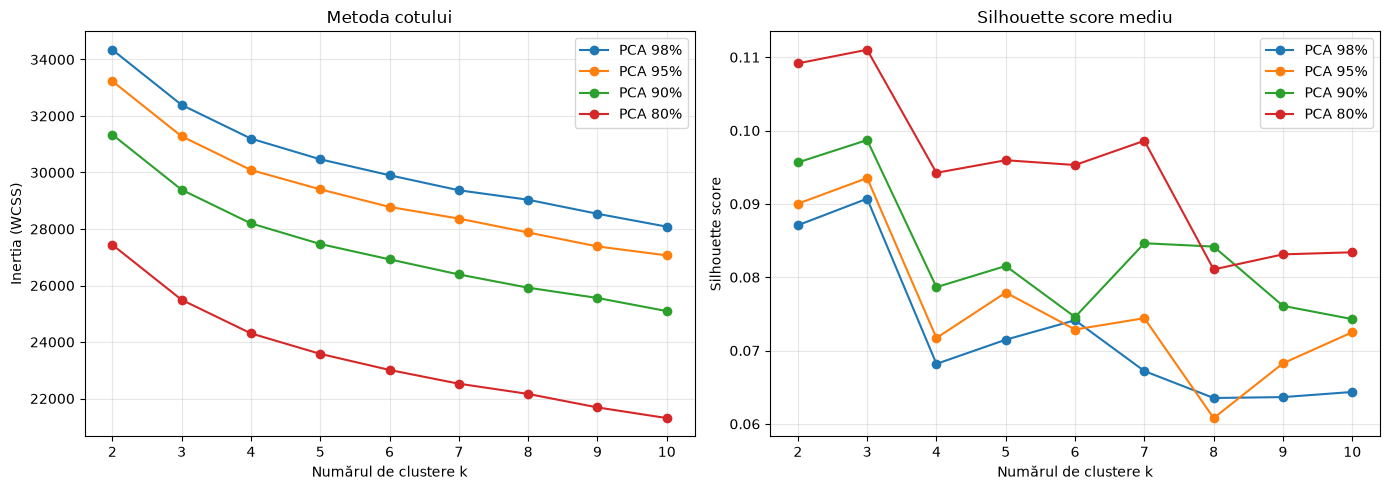

prag,80%,90%,95%,98%
k,,,,
2,0.109,0.096,0.090,0.087
3,0.111,0.099,0.094,0.091
4,0.094,0.079,0.072,0.068
5,0.096,0.082,0.078,0.071
6,0.095,0.075,0.073,0.074
7,0.099,0.085,0.074,0.067
8,0.081,0.084,0.061,0.064
9,0.083,0.076,0.068,0.064
10,0.083,0.074,0.073,0.064


In [3]:
K_RANGE = range(2, 11)

models = {}   # models[(t, k)] = modelul KMeans antrenat, refolosit mai tarziu
rows = []

for t in THRESHOLDS:
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca[t])
        models[(t, k)] = km
        rows.append({
            "prag": f"{t:.0%}",
            "k": k,
            "inertia": km.inertia_,
            "silhouette": silhouette_score(X_pca[t], km.labels_),
        })

elbow = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for t in THRESHOLDS:
    sub = elbow[elbow["prag"] == f"{t:.0%}"]
    axes[0].plot(sub["k"], sub["inertia"], marker="o", label=f"PCA {t:.0%}")
    axes[1].plot(sub["k"], sub["silhouette"], marker="o", label=f"PCA {t:.0%}")

axes[0].set(title="Metoda cotului", xlabel="Numărul de clustere k", ylabel="Inertia (WCSS)")
axes[1].set(title="Silhouette score mediu", xlabel="Numărul de clustere k", ylabel="Silhouette score")
for ax in axes:
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

display(elbow.pivot(index="k", columns="prag", values="silhouette").round(3))

Silhouette score-ul este maxim la k = 3 pentru toate cele patru praguri, iar cotul curbei inertiei
se află în zona k = 3–4. Alegem k = 3.
Valorile silhouette sunt mici (~0,1): casele nu formează grupuri clar separate, ci variază continuu.
Pragurile mai mici au silhouette mai mare, deoarece componentele eliminate conțin mai ales zgomot.
Inertia nu se compară între praguri, ci doar între valori ale lui k pentru același prag.

Silhouette plots:
Pentru k = 2…5 desenăm silhouette coefficient-ul fiecărei case, grupat pe clustere.
Linia roșie este media. Un k bun are clustere care trec de medie și au mărimi comparabile.

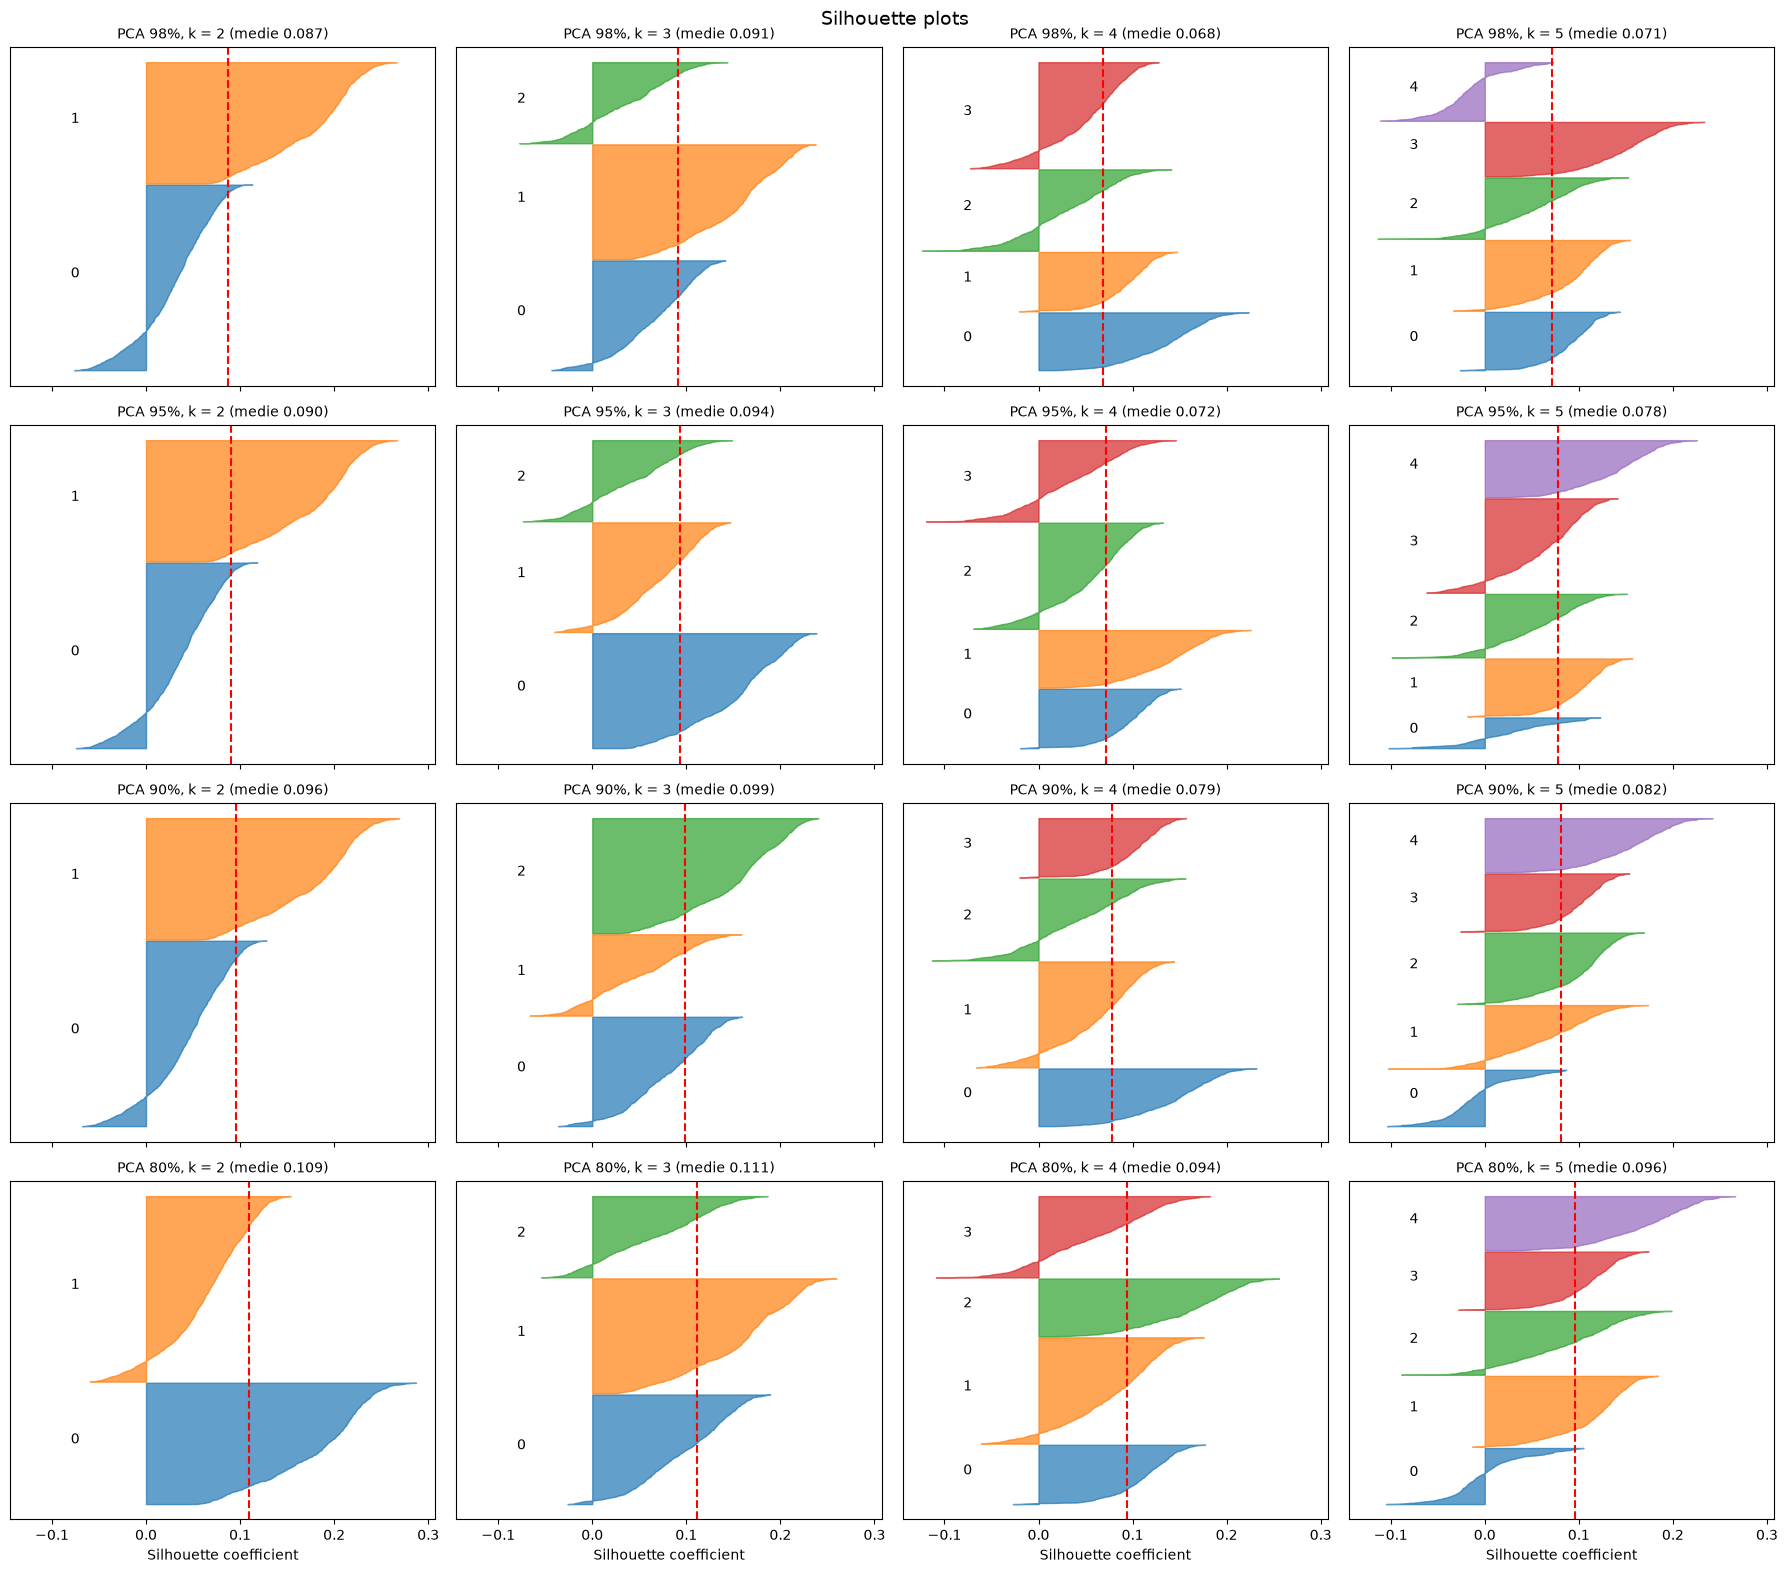

In [4]:
K_SIL = [2, 3, 4, 5]

fig, axes = plt.subplots(len(THRESHOLDS), len(K_SIL), figsize=(18, 16), sharex=True)

for i, t in enumerate(THRESHOLDS):
    for j, k in enumerate(K_SIL):
        ax = axes[i, j]
        labels_tk = models[(t, k)].labels_
        sil = silhouette_samples(X_pca[t], labels_tk)

        y_lower = 10
        for c in range(k):
            vals = np.sort(sil[labels_tk == c])
            y_upper = y_lower + len(vals)
            ax.fill_betweenx(np.arange(y_lower, y_upper), 0, vals,
                             color=plt.cm.tab10(c), alpha=0.7)
            ax.text(-0.08, (y_lower + y_upper) / 2, str(c))
            y_lower = y_upper + 10

        ax.axvline(sil.mean(), color="red", linestyle="--")
        ax.set_title(f"PCA {t:.0%}, k = {k} (medie {sil.mean():.3f})", fontsize=10)
        ax.set_yticks([])

for ax in axes[-1]:
    ax.set_xlabel("Silhouette coefficient")

plt.suptitle("Silhouette plots", fontsize=14)
plt.tight_layout()
plt.show()

Interpretare silhouette plots

- k = 2:unul dintre clustere conține multe case cu silhouette negativ sau apropiat de 0,
  adică slab încadrate. Împărțirea în două grupuri este prea grosieră.
- k = 3:la toate pragurile, toate cele trei clustere depășesc media, au mărimi comparabile
  și puține valori negative. Este cea mai echilibrată împărțire.
- k = 4–5: apar clustere mici, aflate aproape în întregime sub medie, și mai multe case cu
  valori negative. Datele sunt împărțite în prea multe grupuri.

Silhouette plots confirmă alegerea k = 3, în acord cu metoda cotului și cu silhouette score-ul mediu.
Numerotarea și culorile clusterelor sunt arbitrare, deci același grup de case poate avea etichete diferite la praguri diferite.



Clusterele în spațiul primelor două componente principale:
Fiecare casă este un punct (PC1, PC2), colorat după cluster (k = 3). Centroizii sunt marcați cu ✕.

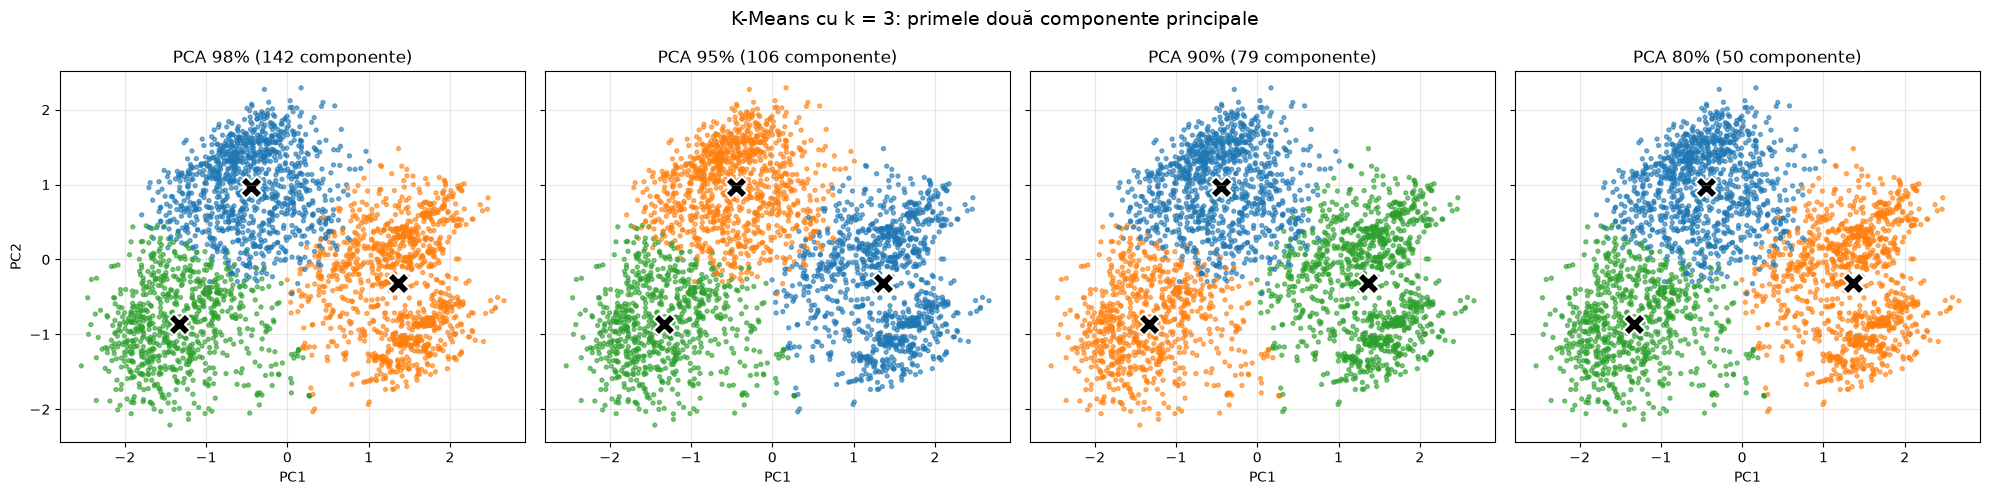

In [5]:
K_BEST = 3

fig, axes = plt.subplots(1, len(THRESHOLDS), figsize=(20, 5), sharex=True, sharey=True)

for ax, t in zip(axes, THRESHOLDS):
    km = models[(t, K_BEST)]
    ax.scatter(X_pca[t][:, 0], X_pca[t][:, 1], c=km.labels_, cmap="tab10",
               vmin=0, vmax=9, s=8, alpha=0.6)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
               c="black", marker="X", s=250, edgecolors="white", linewidths=1.5)
    ax.set(title=f"PCA {t:.0%} ({X_pca[t].shape[1]} componente)", xlabel="PC1")
    ax.grid(alpha=0.3)

axes[0].set_ylabel("PC2")
plt.suptitle(f"K-Means cu k = {K_BEST}: primele două componente principale", fontsize=14)
plt.tight_layout()
plt.show()

Cele patru panouri arată aceleași trei grupuri; diferă doar culorile, deoarece numerotarea clusterelor este arbitrară.
Și centroizii se află în aceleași poziții. Explicația: PCA este „încuibat”, adică PC1 și PC2 sunt identice la toate pragurile,
iar pragurile mai mari doar adaugă componente cu varianță mică, care schimbă foarte puțin distanțele dintre case.

În planul PC1–PC2 clusterele par bine separate, deși silhouette score-ul este mic (~0,1). PC1 și PC2 explică
doar ~19% din varianță, iar silhouette se calculează în toate dimensiunile, unde restul componentelor apropie grupurile.



Comparația între praguri (ARI):
Adjusted Rand Index măsoară cât de asemănătoare sunt două clusterizări, indiferent de numerotarea clusterelor
(1 = identice, 0 = nu mai asemănătoare decât una aleatoare).

In [6]:
labels_by_t = {t: models[(t, K_BEST)].labels_ for t in THRESHOLDS}

ari = pd.DataFrame(
    [[adjusted_rand_score(labels_by_t[a], labels_by_t[b]) for b in THRESHOLDS] for a in THRESHOLDS],
    index=[f"{t:.0%}" for t in THRESHOLDS],
    columns=[f"{t:.0%}" for t in THRESHOLDS],
)
display(ari.round(3))

,98%,95%,90%,80%
98%,1.000,0.999,0.996,0.998
95%,0.999,1.000,0.997,0.999
90%,0.996,0.997,1.000,0.998
80%,0.998,0.999,0.998,1.000


ARI este ≥ 0,996 între toate pragurile: clusterizările sunt practic identice, doar câteva case de la granița
dintre clustere își schimbă grupul. Componentele adăugate peste 80% nu influențează clusterele, deci
pragul de 80% (50 de componente) este suficient și mai eficient.

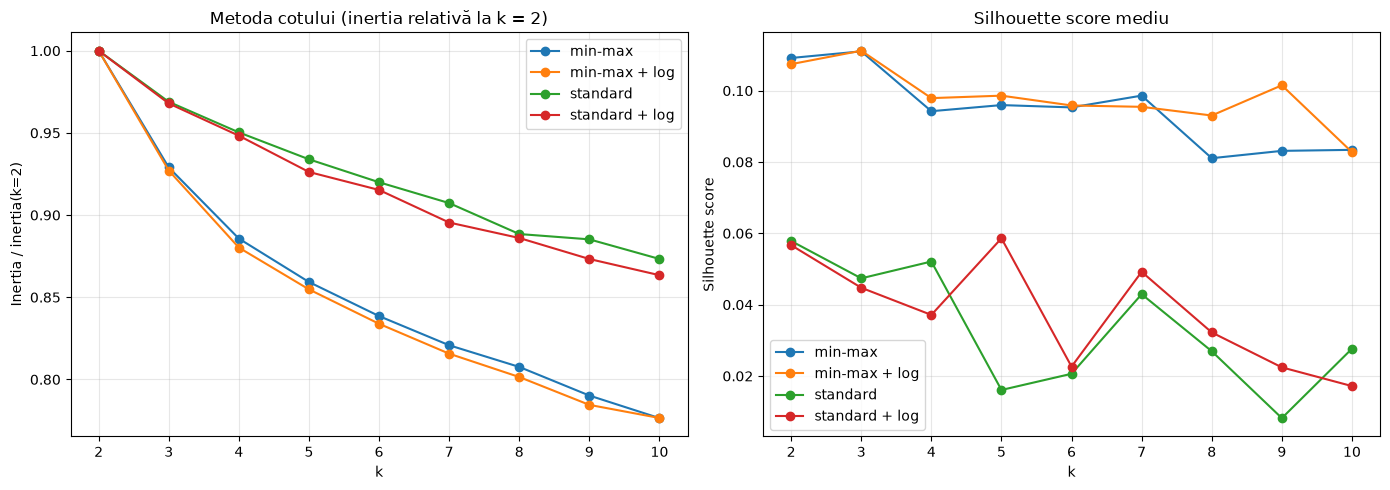

varianta,min-max,min-max + log,standard,standard + log
k,,,,
2,0.109,0.107,0.058,0.057
3,0.111,0.111,0.047,0.045
4,0.094,0.098,0.052,0.037
5,0.096,0.099,0.016,0.059
6,0.095,0.096,0.021,0.023
7,0.099,0.095,0.043,0.049
8,0.081,0.093,0.027,0.032
9,0.083,0.102,0.008,0.022
10,0.083,0.083,0.028,0.017


In [7]:
VARIANTS = {
    "min-max":       dict(scaling="minmax",   log=False),
    "min-max + log": dict(scaling="minmax",   log=True),
    "standard":      dict(scaling="standard", log=False),
    "standard + log": dict(scaling="standard", log=True),
}
T_CMP = 0.80

X_var, var_models, rows = {}, {}, []
for name, params in VARIANTS.items():
    Xs, _, _ = preprocess(df, **params)
    X_var[name] = PCA(n_components=T_CMP, svd_solver="full").fit_transform(Xs)
    for k in K_RANGE:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_var[name])
        var_models[(name, k)] = km
        rows.append({"varianta": name, "k": k, "inertia": km.inertia_,
                     "silhouette": silhouette_score(X_var[name], km.labels_)})

var_res = pd.DataFrame(rows)
var_res["inertia_rel"] = var_res["inertia"] / var_res.groupby("varianta")["inertia"].transform("first")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name in VARIANTS:
    sub = var_res[var_res["varianta"] == name]
    axes[0].plot(sub["k"], sub["inertia_rel"], marker="o", label=name)
    axes[1].plot(sub["k"], sub["silhouette"], marker="o", label=name)

axes[0].set(title="Metoda cotului (inertia relativă la k = 2)", xlabel="k", ylabel="Inertia / inertia(k=2)")
axes[1].set(title="Silhouette score mediu", xlabel="k", ylabel="Silhouette score")
for ax in axes:
    ax.set_xticks(list(K_RANGE))
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

display(var_res.pivot(index="k", columns="varianta", values="silhouette").round(3))

Min-max și min-max + log dau rezultate aproape identice, cu silhouette maxim la k = 3 (0.111).
Cu standardizare, silhouette score-ul e de 2-3 ori mai mic (sub 0.06) și sare mult de la un k la altul, iar inerția scade aproape liniar, fără cot.
Nici k-ul cel mai bun nu mai e același: k = 2 la standard și k = 5 la standard + log. Practic K-Means nu mai găsește o structură clară.
Logaritmarea are un efect mic și neconsecvent la standardizare: la unele valori ale lui k ajută, la altele nu.

Explicația noastră: standardizarea dă varianța 1 fiecărei coloane, inclusiv coloanelor one-hot rare.
O categorie pe care o au doar 1% din case ajunge la valoarea de aproximativ 10, așa că distanțele sunt influențate mult de case cu caracteristici rare.
În plus, e nevoie de mult mai multe componente (125 față de 50 la 80%).
La min-max varianța vine mai ales din coloanele one-hot frecvente, iar logaritmarea schimbă doar coloanele continue, de aceea aproape nu contează.

Min-max este scalarea potrivită pentru aceste date.

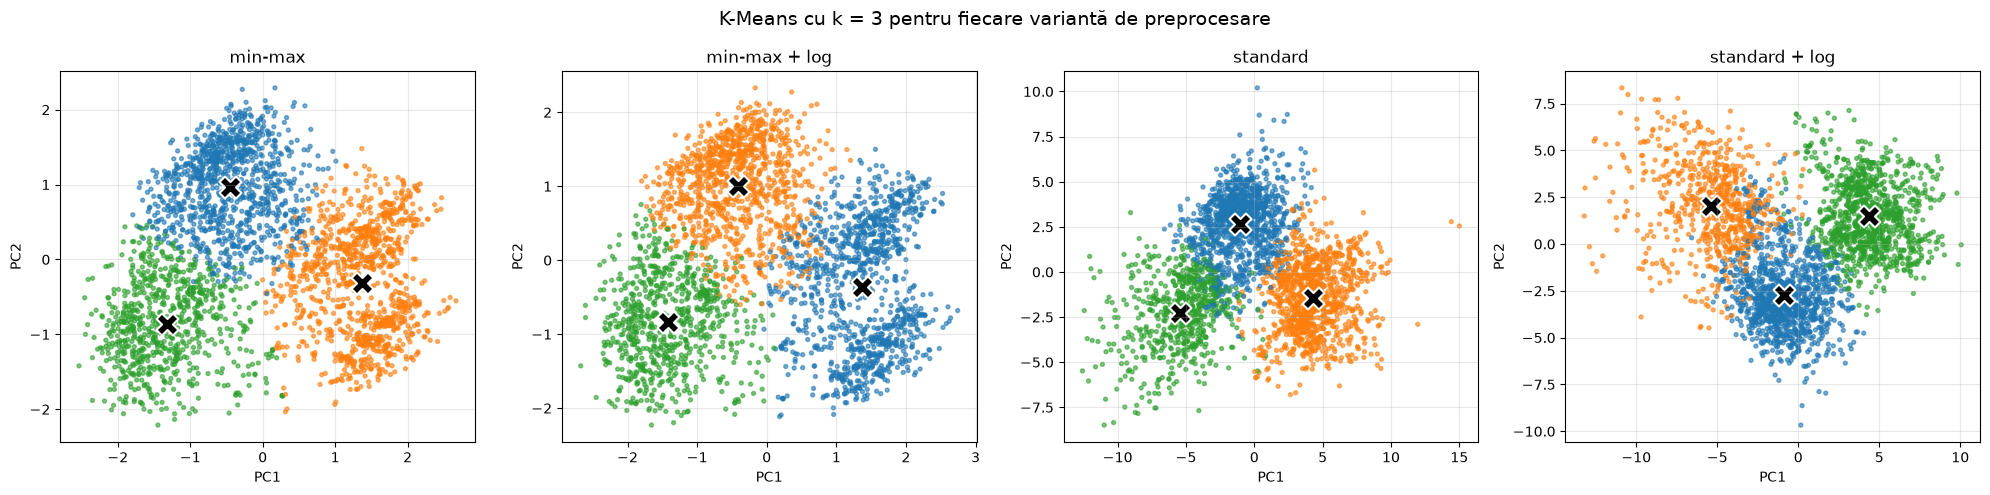

,varianta,marimi_clustere,ARI_fata_de_min-max
0,min-max,"[1102, 1050, 778]",1.000
1,min-max + log,"[1113, 1047, 770]",0.959
2,standard,"[1173, 1105, 652]",0.776
3,standard + log,"[1132, 1097, 701]",0.757


In [8]:
#scatter PC1/PC2, marimea clusterelor si ARI fata de min-max (k = 3)
base = var_models[("min-max", K_BEST)].labels_

fig, axes = plt.subplots(1, len(VARIANTS), figsize=(20, 5))
rows = []
for ax, name in zip(axes, VARIANTS):
    km = var_models[(name, K_BEST)]
    Xp = X_var[name]
    ax.scatter(Xp[:, 0], Xp[:, 1], c=km.labels_, cmap="tab10", vmin=0, vmax=9, s=8, alpha=0.6)
    ax.scatter(km.cluster_centers_[:, 0], km.cluster_centers_[:, 1],
               c="black", marker="X", s=250, edgecolors="white", linewidths=1.5)
    ax.set(title=name, xlabel="PC1", ylabel="PC2")
    ax.grid(alpha=0.3)
    rows.append({
        "varianta": name,
        "marimi_clustere": sorted(np.bincount(km.labels_), reverse=True),
        "ARI_fata_de_min-max": round(adjusted_rand_score(base, km.labels_), 3),
    })

plt.suptitle(f"K-Means cu k = {K_BEST} pentru fiecare variantă de preprocesare", fontsize=14)
plt.tight_layout()
plt.show()

display(pd.DataFrame(rows))

Cu min-max + log am obținut aproape aceleași clustere ca la min-max simplu (ARI 0.959), deci logaritmarea nu schimbă mare lucru aici.

La variantele cu standardizare se păstrează tot 3 grupuri cu mărimi apropiate, dar destul de multe case ajung în alt cluster (ARI 0.78 și 0.76).
În grafice se văd și câteva puncte izolate, departe de restul. Credem că sunt casele cu categorii rare, care după standardizare ajung să conteze mult mai mult decât ar trebui.
Clusterele se suprapun și mai mult, ceea ce se potrivește cu silhouette score-ul mai mic de la standardizare.

Unele grafice par oglindite, dar asta e doar pentru că semnul componentelor din PCA poate ieși diferit.

Pentru modelul final am rămas la min-max, fără log, cu k = 3.

In [9]:
import joblib

T_FINAL = 0.80

labels_df = pd.DataFrame({f"cluster_{t:.0%}".replace("%", ""): models[(t, K_BEST)].labels_ for t in THRESHOLDS},
                         index=X_scaled.index)
labels_df["cluster"] = labels_df[f"cluster_{T_FINAL:.0%}".replace("%", "")]
labels_df.to_csv(DATA_PROCESSED / "lab3_clusters.csv")

joblib.dump(
    {"pipeline": pipeline, "pca": pcas[T_FINAL], "kmeans": models[(T_FINAL, K_BEST)]},
    DATA_PROCESSED / "lab3_kmeans_final.joblib",
)

labels = labels_df["cluster"].to_numpy()
display(cluster_profile(df, labels)[["n_houses", "SalePrice", "Gr Liv Area", "Overall Qual", "Year Built"]].round(1))

,n_houses,SalePrice,Gr Liv Area,Overall Qual,Year Built
cluster,,,,,
0,1050,156634.4,1330.8,5.5,1966.1
1,1102,243140.6,1749.0,7.3,2001.0
2,778,125096.9,1374.4,5.2,1936.5


Am verificat profilul clusterelor cu funcția din Partea 1. Clusterele se diferențiază mai ales după anul construcției și calitate:
clusterul 1 are case noi (în medie din 2001), de calitate bună și cele mai scumpe, clusterul 0 are case din anii '60 cu preț mediu,
iar clusterul 2 are case vechi (în medie din 1936), cele mai ieftine, deși nu sunt cele mai mici.
Prețul nu a fost folosit la clustering, dar clusterele ies totuși ordonate după preț.

Concluzie

Am antrenat K-Means pe datele reduse cu PCA la 98%, 95%, 90% și 80% din varianță. Metoda cotului, silhouette score-ul și
silhouette plots au indicat k = 3 la toate pragurile. Clusterele obținute sunt practic aceleași indiferent de prag (ARI peste 0.99),
pentru că primele componente sunt aceleași și cele adăugate în plus au varianță mică. De aceea 80% e suficient.

Silhouette score-ul e mic (în jur de 0.1), deci casele nu formează grupuri foarte clar separate, ci mai degrabă variază continuu.

La scalare, min-max a mers cel mai bine. Standardizarea a dat clustere mai slabe, pentru că amplifică variabilele one-hot rare.
Logaritmarea a schimbat foarte puțin rezultatele la min-max și a ajutat doar puțin la standardizare.